# 01 · A cost model from the measured costs

`AdaptationMatrix.calibrate()` fits the backtesters' cost formulas on the 424 measured days
(decision 0017), using only inputs that daily bars give on any Massive plan: 21-day dollar
volume, 63-day volatility and the year. The results ship as defaults:
`unimatrix_zero.SPREAD_FIT` (`CostModel(spread="fitted")`, used by the optimizer and execution
too) and tactical-cube's time-of-day multipliers.

1. the fitted spread against the former volume rule
2. out of sample: the last six months, fitted on everything before
3. spreads across the years
4. the close against the quote
5. time of day
6. impact
7. ETFs are not stocks

All measures are **half-spreads in basis points of the midpoint**.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from adaptation_matrix import AdaptationMatrix
from subspace_probe import style
from unimatrix_zero import SPREAD_FIT, CostModel

style()
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
pl.Config.set_float_precision(2)
pl.Config.set_tbl_hide_dataframe_shape(True)
m = AdaptationMatrix()
cal = m.calibrate(write=False)                  # inputs cached in _calibration/; about 10 s
inputs = m.calibration_inputs()
s = cal.spread
print(f"{s.rows:,} stock-days with at least 20 matched trades; adv slope {s.adv_slope:.3f}, "
      f"vol slope {s.vol_slope:.3f}, knots {[(f'${k / 1e6:.0f}M', round(c, 3)) for k, c in s.knots]}")

2,143,076 stock-days with at least 20 matched trades; adv slope -0.388, vol slope 0.624, knots [('$1M', -0.112), ('$10M', 0.133)]


## 1 · The fitted spread and the former rule

The fit is a Poisson regression (log link) of each stock-day's dollar-weighted effective
half-spread on log dollar volume (with slope changes at $1M and $10M a day), log volatility and a
level per year: it predicts the **mean** cost, which is what a trade pays on average. The former
rule, 30 bp × (ADV in $M)^-0.5, was set from quoted spreads.

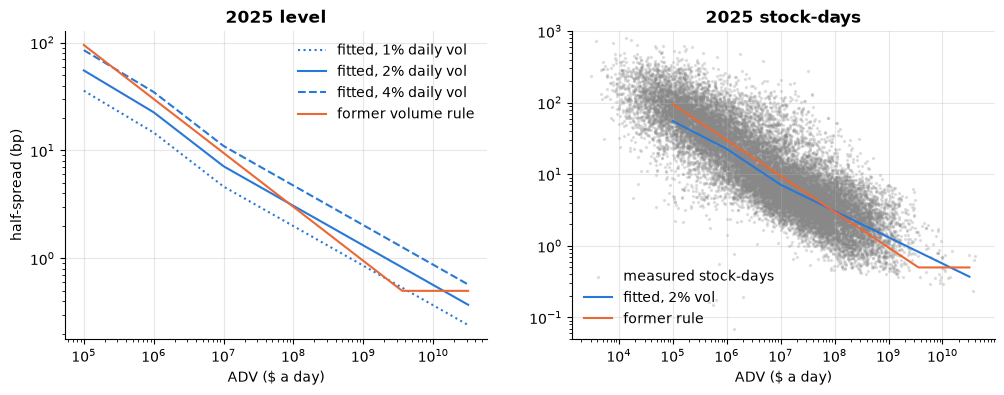

In [2]:
adv = np.logspace(5, 10.5, 200)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for vol, ls in ((0.01, ":"), (0.02, "-"), (0.04, "--")):
    ax[0].plot(adv, s.predict(adv, np.full_like(adv, vol), np.full_like(adv, 2025)), ls=ls, color="#2a78d6",
               label=f"fitted, {vol:.0%} daily vol")
ax[0].plot(adv, np.clip(30 * (adv / 1e6) ** -0.5, 0.5, 200), color="#eb6834", label="former volume rule")
ax[0].set(xscale="log", yscale="log", xlabel="ADV ($ a day)", ylabel="half-spread (bp)", title="2025 level")
ax[0].legend()
d = inputs.filter(pl.col("class") == "stock", pl.col("n_matched") >= 20, pl.col("outside_share") < 0.2,
                  pl.col("date").dt.year() == 2025, pl.col("adv") > 0, pl.col("vol") > 0).sample(20_000, seed=1)
ax[1].scatter(d["adv"], d["eff_bps"], s=2, alpha=0.2, color="#888888", label="measured stock-days")
ax[1].plot(adv, s.predict(adv, np.full_like(adv, 0.02), np.full_like(adv, 2025)), color="#2a78d6", label="fitted, 2% vol")
ax[1].plot(adv, np.clip(30 * (adv / 1e6) ** -0.5, 0.5, 200), color="#eb6834", label="former rule")
ax[1].set(xscale="log", yscale="log", ylim=(0.05, 1000), xlabel="ADV ($ a day)", title="2025 stock-days")
ax[1].legend()
plt.show()

Volatility matters as much as volume: a stock twice as volatile pays about 1.5 times the spread
(slope 0.62). The former rule had no volatility term, so it charged a quiet utility and a
biotech of the same volume alike.

## 2 · Out of sample

Fitted on every measured day before the last six months, then compared with those six months
(stocks, days with at least 20 matched trades). `*_ratio` is the median of predicted over
measured per stock-day; `*_dw_ratio` sums predicted and measured costs weighted by dollar
volume, which is what a portfolio's trades pay.

In [3]:
cal.validation

size,stock_days,measured_bps,fit_bps,fit_ratio,fit_dw_ratio,rule_bps,rule_ratio,rule_dw_ratio
str,u32,f64,f64,f64,f64,f64,f64,f64
"""<1M""",183423,86.27,80.87,1.18,0.95,80.87,1.20,0.96
"""1-10M""",172050,24.68,19.07,1.17,0.91,17.29,1.20,0.87
"""10-100M""",206267,8.47,6.04,1.17,0.85,5.59,1.10,0.75
"""100M-1B""",116105,2.98,2.77,1.14,0.94,2.00,0.84,0.63
"""1-10B""",13463,1.70,1.54,1.02,0.87,0.72,0.51,0.38
""">10B""",1400,0.84,0.80,1.22,0.86,0.50,0.78,0.55


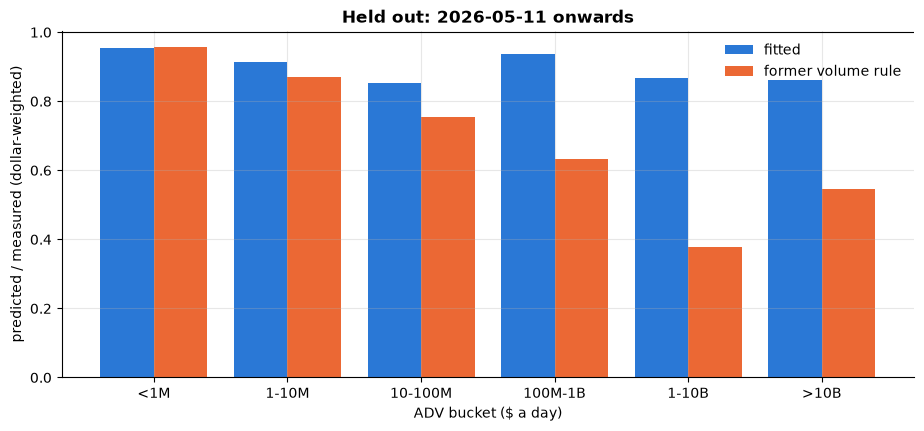

In [4]:
v = cal.validation
x = np.arange(v.height)
fig, ax = plt.subplots()
ax.bar(x - 0.2, v["fit_dw_ratio"], 0.4, color="#2a78d6", label="fitted")
ax.bar(x + 0.2, v["rule_dw_ratio"], 0.4, color="#eb6834", label="former volume rule")
ax.axhline(1, color="k", lw=0.8)
ax.set_xticks(x, v["size"].to_list())
ax.set(xlabel="ADV bucket ($ a day)", ylabel="predicted / measured (dollar-weighted)",
       title=f"Held out: {cal.test_start} onwards")
ax.legend()
plt.show()

## 3 · Across the years

The level per year is the half-spread of a $100M-a-day stock with 2% daily volatility. It fell
from about 3.5 bp in 2003 to 2.3 bp in 2009-2012 and has been 2.9-3.4 bp since 2020.
A backtest charges each trade its own year's level (`spread_cost(at=date)`); years outside the
fit take the nearest one.

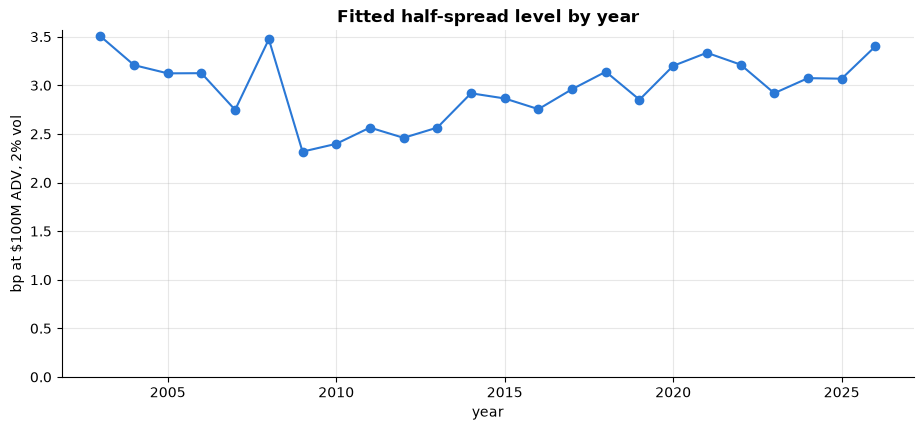

In [5]:
lv = pl.DataFrame({"year": list(s.levels), "bps": list(s.levels.values())})
fig, ax = plt.subplots()
ax.plot(lv["year"], lv["bps"], marker="o", color="#2a78d6")
ax.set(xlabel="year", ylabel="bp at $100M ADV, 2% vol", title="Fitted half-spread level by year", ylim=(0, None))
plt.show()
assert dict(SPREAD_FIT.levels) == {y: round(v, 4) for y, v in s.levels.items()}, "SPREAD_FIT is stale"

## 4 · The close against the quote

The official close against the midpoint just before the close, for the last three years. Its
signed median is 0 bp in every size bucket: a market-on-close order of either side pays no
spread on average, and the close is also the backtest's mark. `CostModel(auction=True)` models
that (no half-spread; commission and impact remain). It is off by default, because without an
AUM it would make closing-auction trades nearly free however thin the auction:
`auction_share` is the closing auction's share of the day's volume.

In [6]:
cal.close

size,stock_days,signed_median_bps,signed_mean_bps,abs_mean_bps,preclose_qhs_bps,auction_share
str,u32,f64,f64,f64,f64,f64
"""<1M""",259095,-4.62,-11.28,94.41,80.81,0.01
"""1-10M""",235086,0.00,-1.76,32.88,15.24,0.09
"""10-100M""",274072,-0.00,-0.44,11.19,4.65,0.17
"""100M-1B""",149425,-0.26,-0.15,3.95,2.06,0.20
"""1-10B""",16610,0.00,-0.01,3.29,1.36,0.18
""">10B""",1631,0.00,0.32,3.77,1.11,0.12


## 5 · Time of day

The effective half-spread in each part of the session relative to the day's dollar-weighted
spread (which the fitted model predicts), for stocks over $10M a day on the last 60 measured
sessions. These are tactical-cube's new multipliers.

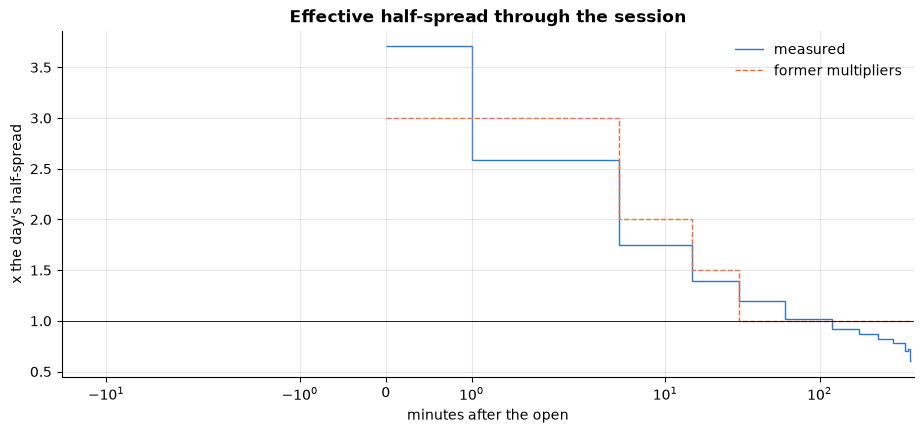

((1, 3.71), (5, 2.58), (15, 1.75), (30, 1.39), (60, 1.2), (120, 1.02), (180, 0.92), (240, 0.87), (300, 0.82), (360, 0.78), (375, 0.7), (385, 0.72), (390, 0.6))


In [7]:
t = cal.tod
starts = t["start_minute"].to_list()
ends = starts[1:] + [390]
fig, ax = plt.subplots()
ax.stairs(t["multiplier"].to_numpy(), [0] + ends, color="#2a78d6", label="measured", baseline=None)
ax.stairs([3.0, 2.0, 1.5, 1.0], [0, 5, 15, 30, 390], color="#eb6834", ls="--", label="former multipliers", baseline=None)
ax.axhline(1, color="k", lw=0.6)
ax.set(xscale="symlog", xlabel="minutes after the open", ylabel="x the day's half-spread",
       title="Effective half-spread through the session")
ax.legend()
plt.show()
print(cal.tod_pairs())

## 6 · Impact

The session's mid return (open + 1 minute to the pre-close mid, net of the median large stock),
in units of daily volatility, against the square root of the day's Lee-Ready net dollar flow as
a share of ADV. The slope is comparable with `CostModel.impact_coef` (1.0). Tape flow mixes
informed and uninformed orders, so read it as a range: 0.7-1.0 for most sizes, noisier above
$1B a day. The default stays 1.0; your own fills (transwarp-conduit) are the check.

In [8]:
cal.impact

size,stock_days,impact_coef,median_abs_flow,pi_5m_bps
str,u32,f64,f64,f64
"""<1M""",230650,0.85,0.11,36.51
"""1-10M""",229887,0.99,0.06,14.66
"""10-100M""",272272,0.84,0.04,5.82
"""100M-1B""",148921,0.72,0.03,2.35
"""1-10B""",16559,1.14,0.03,1.29
""">10B""",1601,1.45,0.03,0.62
"""all""",899890,0.87,0.05,15.28


## 7 · ETFs are not stocks

The spread was fitted on stocks. Index ETFs trade far tighter than stocks of the same volume and
volatility, and their spread hardly changes through the day, so the stock model (and its 0.5 bp
floor) overcharges them. Use an ETF's own measured spread instead, as the intraday trials do.

In [9]:
etf = (m.daily(["SPY", "QQQ", "IWM"], "2026-05-01").filter(pl.col("outside_share") < 0.2)
       .group_by("ticker").agg(((pl.col("eff_bps") * pl.col("dollar_volume")).sum() / pl.col("dollar_volume").sum())
                               .alias("measured_bps"))
       .join(inputs.filter(pl.col("date") >= pl.date(2026, 5, 1)).group_by("ticker")
             .agg(pl.col("adv").mean(), pl.col("vol").mean()), on="ticker"))
etf.with_columns(fitted_bps=CostModel(commission_bps=0.0).spread_cost(2026) * 1e4).sort("ticker")

ticker,measured_bps,adv,vol,fitted_bps
str,f64,f64,f64,f64
"""IWM""",0.21,6883074081.37,0.01,0.50
"""QQQ""",0.16,28305662147.58,0.01,0.50
"""SPY""",0.12,35669130271.02,0.01,0.50


## What it says

- The former rule charged names over $100M a day 37-62% too little (dollar-weighted). The
  fitted spread is within 5-15% of measured costs in every size bucket out of sample, and it
  moves with volatility and with the year.
- The close costs nothing against the pre-close mid on average, in every size bucket; whether a
  backtest should charge it a half-spread is a choice (`CostModel(auction=...)`), not a measurement.
- The opening minutes cost 2.5-3.7 times the day's spread and the last hour 0.6-0.8 times: the
  former multipliers were too low at the open and too high in the afternoon.
- Impact from tape flow is in line with the square-root coefficient of 1.0 already in use.